## Perceptron learning

In the first part of this exercise we will reproduce the Figures in Chapter 39 of the MacKay book.

$x$ is an $p \times N$ matrix containing all the N-dimensional input vectors for each of the p patterns. We set $N=2$ and use an explicit fixed bias $b$ (we called it $w_0$ in the class) in the perceptron activation; w[0] and w[1] are the weights.

$z$ is a vector of length p containing the targets for each training pattern, each target $\in$ {0,1}. In class we used the notation: $z^\mu$ and $x^\mu_i$.

We can choose three pattern arrangements: two clusters (`separable`), an XOR-like arrangement (`nonseparable`), or the `weird` arrangement.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
np.random.seed(1)  # Get the same random data each time we run the notebook.

## Generate training set

**Goal**: Generate two labeled groups in two dimensions, then compare a cluster arrangement, an XOR-like arrangement, and the `weird` arrangement.

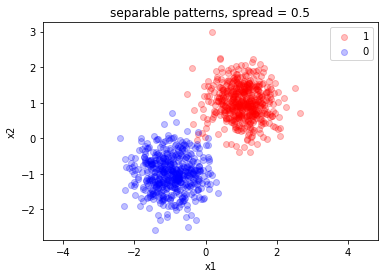

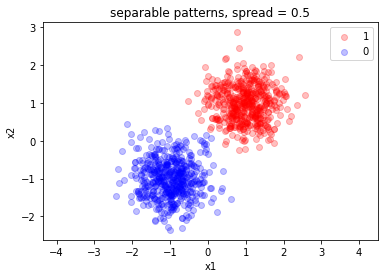

In [2]:
def generate_patterns(spread, N=2, p1=100, p2=100,
                      option="separable", plot=False):
    # This lab uses two features so that we can plot the points.
    if N != 2:
        raise ValueError("This function requires N=2.")

    # Start with one group near (1, 1) and another near (-1, -1).
    x1 = 1 + spread * np.random.randn(p1, N)
    x0 = -1 + spread * np.random.randn(p2, N)

    # Give the first group label 1 and the second group label 0.
    z1 = np.ones(p1)
    z0 = np.zeros(p2)

    if option == "nonseparable":
        # Place each class in two opposite corners (an XOR pattern).
        x1[:p1 // 2] *= -1
        x0[:p2 // 2, 1] *= -1
        x0[p2 // 2:, 0] *= -1

    elif option == "weird":
        # Equal group sizes give equal numbers of labels 1 and 0.
        if p1 != p2:
            raise ValueError("Use p1=p2 for balanced weird patterns.")

        # Move half of class 1, but keep its label as 1.
        x1[:p1 // 2] = 1.5 - x1[:p1 // 2]

        # Move class 0 into two different regions.
        x0[:p2 // 2, 1] = 1 - x0[:p2 // 2, 1]
        x0[p2 // 2:, 0] *= -1

    elif option != "separable":
        raise ValueError("Choose 'separable', 'nonseparable', or 'weird'.")

    # Combine the two groups and their labels.
    x = np.vstack((x1, x0))
    z = np.concatenate((z1, z0))

    if plot:
        # Color each point by its target label.
        fig, ax = plt.subplots()
        ax.scatter(x[z == 1, 0], x[z == 1, 1],
                   color="red", alpha=0.25, label="1")
        ax.scatter(x[z == 0, 0], x[z == 0, 1],
                   color="blue", alpha=0.25, label="0")
        ax.set_title(f"{option} patterns, spread = {spread}")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.axis("equal")
        ax.legend()

    return x, z

p1=500
p2=500
N=2
spread=.5
x,z=generate_patterns(spread=spread,N=N,p1=p1,p2=p2,option='separable',plot=True)
x_test,z_test=generate_patterns(spread=spread,N=N,p1=p1,p2=p2,option='separable',plot=True)


## Activity rule and cost functions
Activity: 
$$
f(h)={1\over 1+e^{-h}}
$$

Negative log-likelihood function: 
$$
G(w;X,z,b)=-\sum_{\mu=1}^p\left[z^\mu\ln f(h^\mu)+(1-z^\mu)\ln(1- f(h^\mu))\right]\ , \,\,h^\mu=\sum_{i=1}^Nw_ix_i^\mu+b
$$

Negative log-posterior: 
$$
M(w;X,z,b)=G(z^\mu|x^\mu_i,w_i)+{1\over2}\alpha \sum_{i=1}^Nw_i^2
$$

The weight regularization term ${1\over2}\alpha \sum_{i=1}^Nw_i^2$ corresponds to a Gaussian prior on the weights.

### From the definition of $G$ to the code

The formula above defines the negative log-likelihood:

$$
G=-\sum_{\mu=1}^{p}
\left[
z^\mu\log f(h^\mu)
+(1-z^\mu)\log(1-f(h^\mu))
\right],
\qquad
h^\mu=w\cdot x^\mu+b.
$$

We can rewrite it using the sigmoid:

$$
f(h)=\frac{1}{1+e^{-h}}=\frac{e^h}{1+e^h}.
$$

This gives us two identities:

$$
\log f(h)=h-\log(1+e^h),
\qquad
\log(1-f(h))=-\log(1+e^h).
$$

Now consider **one** training pattern. Substitute these identities into
its contribution to $G$:

$$
\begin{aligned}
-\left[z\log f(h)+(1-z)\log(1-f(h))\right]
&=-z\left[h-\log(1+e^h)\right]
  -(1-z)\left[-\log(1+e^h)\right] \\
&=-zh+\left[z+(1-z)\right]\log(1+e^h) \\
&=\log(1+e^h)-zh.
\end{aligned}
$$

Finally, add this contribution over all training patterns:

$$
G=\sum_{\mu=1}^{p}
\left[\log(1+e^{h^\mu})-z^\mu h^\mu\right].
$$

In the code, `np.logaddexp(0, h)` computes $\log(1+e^h)$ for every
pattern, `z * h` computes $zh$, and `np.sum` adds the contributions.
`np.logaddexp` avoids numerical overflow when $h$ is large.

In [3]:
# activity rule
b = -1  # Keep the bias fixed during training.

def sigmoid(h):
    # Convert activation h into the probability of class 1.
    return 1 / (1 + np.exp(-h))

def Gfunc(w, x, z, b):
    # Compute each pattern's activation.
    h = x @ w + b

    # For each pattern, logaddexp(0, h) computes log(1 + exp(h))
    # without numerical overflow. Subtracting z*h gives that pattern's
    # negative log-likelihood; np.sum adds it over all patterns.
    return np.sum(np.logaddexp(0, h) - z * h)

## Batch training with the sigmoid model

In each training step, we use all $p$ patterns to update the weights.
For pattern $\mu$, the model output is $y^\mu=f(h^\mu)$.

$$
w_i \leftarrow w_i+\eta\left[
\sum_{\mu=1}^{p}(z^\mu-y^\mu)x_i^\mu-\alpha w_i
\right].
$$

The sum moves the weight toward better predictions. The term
$-\alpha w_i$ shrinks the weight toward zero; it appears once per
update, outside the sum.

Note: In the calculation of the gradient of the loss function leading to the learning rule, the sigmoid derivative $y^\mu(1-y^\mu)$ cancels the corresponding
factor from differentiating the cross-entropy loss, leaving
$y^\mu-z^\mu$ in the gradient.

In [4]:
T = 2000
plot_every = 20    # Save one point for the plots every 20 steps.
print_every = 200  # Print one progress report every 200 steps.

eta = 0.0001
alpha = 1.0
w = 2 * np.random.randn(x.shape[1])

print("Initial weights:", w)

# Store the values we want to plot.
step_history = []
w_history = []
G_history_train = []
M_history_train = []
G_history_test = []
M_history_test = []
train_error = []
test_error = []

for step in range(1, T + 1):
    # Predict the probability of class 1 for each training pattern.
    y = sigmoid(x @ w + b)

    # Compute the gradient of G plus the weight-decay term.
    gradient = - (z-y) @ x + alpha * w

    # Update both weights using the full training set.
    w = w - eta * gradient

    if step % plot_every == 0:
        # Evaluate both sets using the updated weights.
        y_train = sigmoid(x @ w + b)
        y_test = sigmoid(x_test @ w + b)

        # Record costs, weights, and classification errors.
        G = Gfunc(w, x, z, b)
        M = G + 0.5 * alpha * (w @ w)

        step_history.append(step)
        w_history.append(w.copy())
        G_history_train.append(G)
        M_history_train.append(M)
        G_history_test.append(Gfunc(w, x_test, z_test, b))
        M_history_test.append(G_history_test[-1] + 0.5 * alpha * (w @ w))
        train_error.append(np.mean((y_train >= 0.5) != z))
        test_error.append(np.mean((y_test >= 0.5) != z_test))

        if step % print_every == 0:
            print(
                f"step {step:4d} | G = {G:7.3f} | M = {M:7.3f} | "
                f"train error = {train_error[-1]:.3f} | "
                f"test error = {test_error[-1]:.3f} | "
                f"w1 = {w[0]:.4f}, w2 = {w[1]:.4f}"
            )

# Report the weights after the final training step.
print(f"Final weights: w1 = {w[0]:.4f}, w2 = {w[1]:.4f}")

Initial weights: [-0.28074199  0.28328335]
step  200 | G =  60.404 | M =  64.351 | train error = 0.010 | test error = 0.006 | w1 = 1.8019, w2 = 2.1561
step  400 | G =  40.118 | M =  45.899 | train error = 0.007 | test error = 0.002 | w1 = 2.2495, w2 = 2.5500
step  600 | G =  32.788 | M =  39.800 | train error = 0.006 | test error = 0.002 | w1 = 2.5089, w2 = 2.7803
step  800 | G =  28.934 | M =  36.873 | train error = 0.006 | test error = 0.002 | w1 = 2.6884, w2 = 2.9412
step 1000 | G =  26.540 | M =  35.216 | train error = 0.006 | test error = 0.000 | w1 = 2.8230, w2 = 3.0632
step 1200 | G =  24.905 | M =  34.186 | train error = 0.005 | test error = 0.000 | w1 = 2.9286, w2 = 3.1600
step 1400 | G =  23.717 | M =  33.505 | train error = 0.005 | test error = 0.000 | w1 = 3.0140, w2 = 3.2392
step 1600 | G =  22.817 | M =  33.037 | train error = 0.005 | test error = 0.000 | w1 = 3.0845, w2 = 3.3054
step 1800 | G =  22.112 | M =  32.704 | train error = 0.005 | test error = 0.000 | w1 = 3.143

## Plot learning progress and classification boundaries

The first figure shows how the weights, costs, and classification errors
change during training.

The second figure shows points where the model predicts a fixed
probability $q$ of class 1:

$$
q=f(h).
$$

We draw contours for $q=0.25$, $0.5$, and $0.75$. The $0.5$ contour is
the classification boundary. Equivalently, a contour satisfies

$$
h=w_1x_1+w_2x_2+b=\log\left(\frac{q}{1-q}\right).
$$

For some weights, a requested probability may not occur in the region
shown. In that case, its contour does not appear.

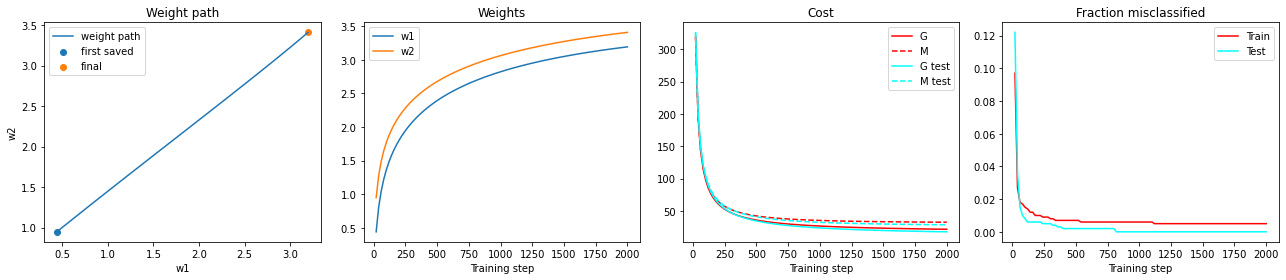

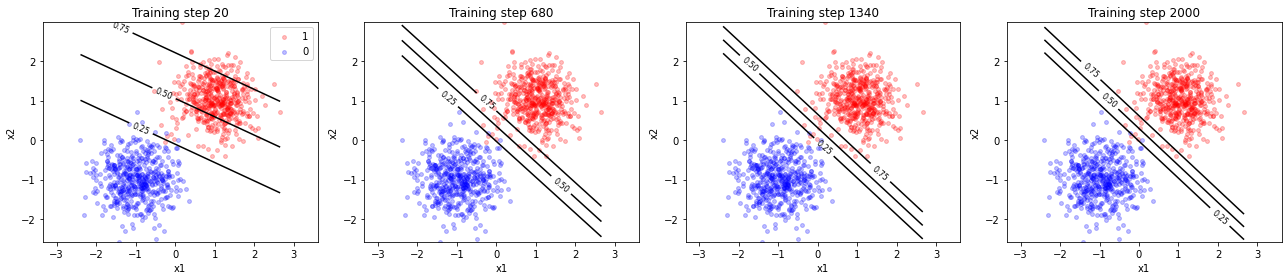

In [5]:

# Convert the saved weight pairs into an array for plotting.
weights = np.array(w_history)

fig, ax = plt.subplots(1, 4, figsize=(18, 4))

# Show the path taken by the two weights.
ax[0].plot(weights[:, 0], weights[:, 1], label="weight path")
ax[0].scatter(weights[0, 0], weights[0, 1], label="first saved")
ax[0].scatter(weights[-1, 0], weights[-1, 1], label="final")
ax[0].set_xlabel("w1")
ax[0].set_ylabel("w2")
ax[0].set_title("Weight path")

# Show each weight as training proceeds.
ax[1].plot(step_history, weights[:, 0], label="w1")
ax[1].plot(step_history, weights[:, 1], label="w2")
ax[1].set_xlabel("Training step")
ax[1].set_title("Weights")

# Show the loss before and after adding weight decay.
ax[2].plot(step_history, G_history_train, label="G", color="red")
ax[2].plot(step_history, M_history_train, label="M", color="red",linestyle = "--")
ax[2].plot(step_history, G_history_test, label="G test", color="cyan")
ax[2].plot(step_history, M_history_test, label="M test", color="cyan",linestyle = "--")
ax[2].set_xlabel("Training step")
ax[2].set_title("Cost")

# Compare classification error on training and test data.
ax[3].plot(step_history, train_error, label="Train", color="red")
ax[3].plot(step_history, test_error, label="Test", color="cyan")
ax[3].set_xlabel("Training step")
ax[3].set_title("Fraction misclassified")

for panel in ax:
    panel.legend()

plt.tight_layout()


# Choose four saved moments during training.
snapshot_indices = [
    0,
    len(weights) // 3,
    2 * len(weights) // 3,
    len(weights) - 1
]

# Make a grid covering the region containing the training points.
x1_values = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
x2_values = np.linspace(x[:, 1].min(), x[:, 1].max(), 100)
X1, X2 = np.meshgrid(x1_values, x2_values)

fig, ax = plt.subplots(1, 4, figsize=(18, 4))

for panel, index in zip(ax, snapshot_indices):
    # Show the training patterns.
    panel.scatter(x[z == 1, 0], x[z == 1, 1],
                  s=15, color="red", alpha=0.25, label="1")
    panel.scatter(x[z == 0, 0], x[z == 0, 1],
                  s=15, color="blue", alpha=0.25, label="0")

    # Predict the probability of class 1 across the grid.
    probability = sigmoid(
        weights[index, 0] * X1 + weights[index, 1] * X2 + b
    )

    # Draw only probability levels that occur in this region.
    levels = []
    for q in (0.25, 0.5, 0.75):
        if probability.min() <= q <= probability.max():
            levels.append(q)

    if levels:
        lines = panel.contour(X1, X2, probability,
                              levels=levels, colors="black")
        panel.clabel(lines, fmt="%.2f", fontsize=8)

    panel.set_title(f"Training step {step_history[index]}")
    panel.set_xlabel("x1")
    panel.set_ylabel("x2")
    panel.axis("equal")

ax[0].legend()
plt.tight_layout()


## Learning as inference

In the second part of this exercise we will reproduce the Figures in Chapter 41 of the MacKay book.

We now keep the training data and bias $b$ fixed, and try many possible
values of the two weights $(w_1,w_2)$.

The quantities $G$ and $M$ above are **negative** log quantities.
Therefore:

$$
\text{log-likelihood}=-G,
$$

$$
\text{log-prior}=-\frac{\alpha}{2}(w_1^2+w_2^2)
\quad\text{up to a constant},
$$

$$
\text{log-posterior}=-M
\quad\text{up to a constant}.
$$

The MAP weights are the pair with the largest log-posterior. This is
equivalent to finding the smallest value of $M$.

The grid below uses a balanced subset of the training set, chosen in
the next cell. Its MAP weights may differ from the final trained weights
because they use different data and the grid tests only discrete values.

The n_per_class variable sets the number of data points to run the analysis. By varying it, you will find out how the sample size affects the MAP estimate.

In [6]:
# Choose the total number of training points to use below.
n_per_class = 5  # per-class number of datapoints

class1_rows = np.where(z == 1)[0]
class0_rows = np.where(z == 0)[0]
if n_per_class > min(len(class1_rows), len(class0_rows)):
    raise ValueError("n_per_class is too large for a balanced sample.")

# Select the same random points each time this cell runs.
rng = np.random.default_rng(2)
chosen1 = rng.choice(class1_rows, n_per_class, replace=False)
chosen0 = rng.choice(class0_rows, n_per_class, replace=False)
plot_rows = np.concatenate((chosen1, chosen0))
x_plot = x[plot_rows]
z_plot = z[plot_rows]
print(f"Using {n_per_class} points from each class ({2*n_per_class} total).")

# Try weight values from -8 to 8.
weight_values = np.linspace(-8, 8, 81)
W1, W2 = np.meshgrid(weight_values, weight_values)

# Store the log-likelihood for each pair of weights.
log_likelihood = np.zeros_like(W1)

for row in range(W1.shape[0]):
    for col in range(W1.shape[1]):
        # Test this weight pair on the selected training points.
        trial_w = np.array([W1[row, col], W2[row, col]])
        log_likelihood[row, col] = -Gfunc(trial_w, x_plot, z_plot, b)

# Compute the log-prior and add it to the log-likelihood.
log_prior = -0.5 * alpha * (W1**2 + W2**2)
log_posterior = log_likelihood + log_prior

# Find the weight pair with the largest log-posterior.
map_row, map_col = np.unravel_index(
    np.argmax(log_posterior), log_posterior.shape
)
w_map = np.array([W1[map_row, map_col],
                  W2[map_row, map_col]])

print(f"Grid MAP weights: w1 = {w_map[0]:.2f}, w2 = {w_map[1]:.2f}")

Using 5 points from each class (10 total).
Grid MAP weights: w1 = 1.20, w2 = 1.00


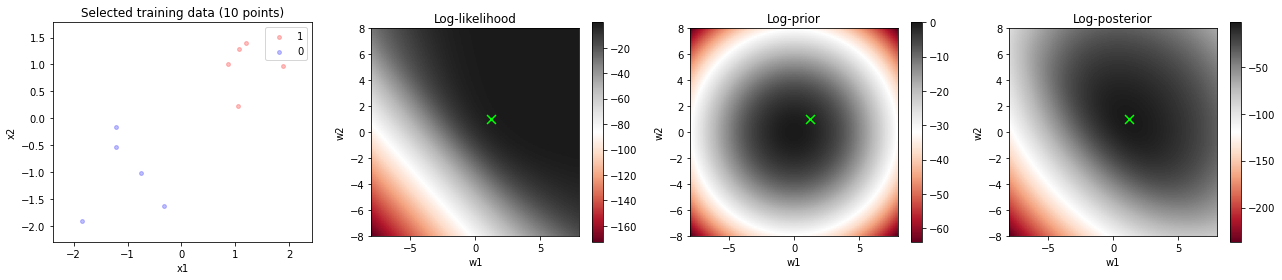

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))

# Show the training data, using its actual labels.
ax[0].scatter(x_plot[z_plot == 1, 0], x_plot[z_plot == 1, 1],
              s=15, color="red", alpha=0.25, label="1")
ax[0].scatter(x_plot[z_plot == 0, 0], x_plot[z_plot == 0, 1],
              s=15, color="blue", alpha=0.25, label="0")
ax[0].set_title(f"Selected training data ({2*n_per_class} points)")
ax[0].set_xlabel("x1")
ax[0].set_ylabel("x2")
ax[0].axis("equal")
ax[0].legend()

# Show each quantity as a function of w1 and w2.
surfaces = [log_likelihood, log_prior, log_posterior]
titles = ["Log-likelihood", "Log-prior", "Log-posterior"]

for i in range(3):
    panel = ax[i + 1]

    # Display the values over the weight grid.
    image = panel.imshow(
        surfaces[i],
        origin="lower",
        extent=[weight_values[0], weight_values[-1],
                weight_values[0], weight_values[-1]],
        cmap="RdGy"
    )

    # Mark the same MAP weight pair on all three plots.
    panel.scatter(w_map[0], w_map[1],
                  color="lime", marker="x", s=80)
    panel.set_title(titles[i])
    panel.set_xlabel("w1")
    panel.set_ylabel("w2")
    fig.colorbar(image, ax=panel)

plt.tight_layout()

## Assignment: choose the weight penalty using validation data

We will investigate how the spread of the two classes affects the best
weight penalty and prediction error.

1. For each spread in $[0.001,0.01,0.05, 0.1, 0.2,0.5]$, generate `n_repeats`=**five independent pairs** of
   training and test sets, $D_{\mathrm{train}}$ and $D_{\mathrm{test}}$.
   Use `generate_patterns` with `option="weird"` and $p_1=p_2=200$
   for **each** set. Each set therefore contains 400 points. Note: we are in a regime where the training set has a small sample size.
2. Split each $D_{\mathrm{train}}$ into a small training set
   $D'_{\mathrm{train}}$ (70%) and a validation set $D_{\mathrm{val}}$ (30%),
   so $D_{\mathrm{train}}=D'_{\mathrm{train}}\cup D_{\mathrm{val}}$.
   Keep the labels balanced in all sets.
3. Train the sigmoid perceptron on $D'_{\mathrm{train}}$ for 5,000 batch
   steps with learning rate $\eta=0.0001$ for each
   $\alpha \in \{0, 0.1, \ldots, 10.0\}$ (the 21 values from
   `np.linspace(0.0, 10.0, 21)`). Choose $\alpha^*$ with the lowest
   fraction misclassified on $D_{\mathrm{val}}$. If values tie, choose the
   smallest $\alpha$. Keep the bias $b=-1$ fixed, as in the lab above.
4. Evaluate the weights selected by validation **once** on the matching
   $D_{\mathrm{test}}$. Do not use test labels to choose $\alpha^*$.
5. Plot the selected $\alpha^*$ values and test error against spread.
   Show all five repetitions, the median $\alpha^*$, and the mean test error.

**Questions:** How does the selected
$\alpha^*$ change with spread? Why?
